Upload your CONTENT image first:


Saving 1.png to 1.png
Upload your STYLE image:


Saving Content and Style Comparison.png to Content and Style Comparison.png


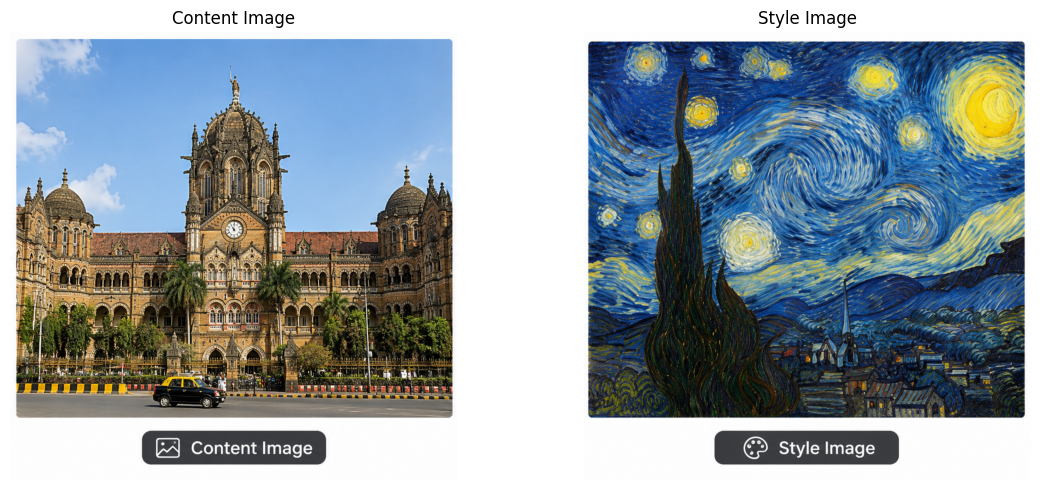

Content size: (887, 887)
Style size: (884, 887)


In [1]:

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

print("Upload your CONTENT image first:")
content_upload = files.upload()

print("Upload your STYLE image:")
style_upload = files.upload()

# Load uploaded images
content_path = list(content_upload.keys())[0]
style_path = list(style_upload.keys())[0]

content_image = Image.open(content_path).convert("RGB")
style_image = Image.open(style_path).convert("RGB")

# Display both images
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(content_image)
axes[0].set_title("Content Image")
axes[0].axis("off")

axes[1].imshow(style_image)
axes[1].set_title("Style Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Content size:", content_image.size)
print("Style size:", style_image.size)


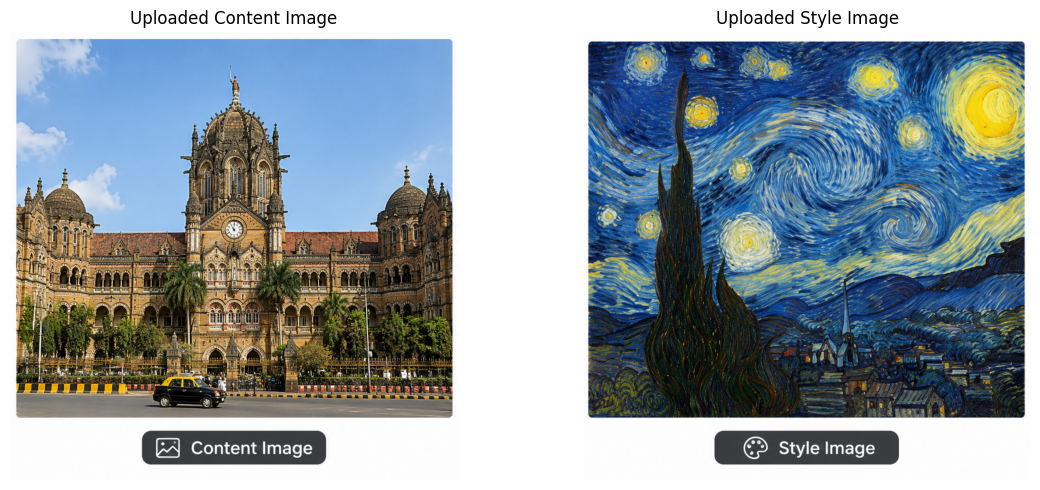

In [2]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(content_image)
axes[0].set_title("Uploaded Content Image")
axes[0].axis("off")

axes[1].imshow(style_image)
axes[1].set_title("Uploaded Style Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()


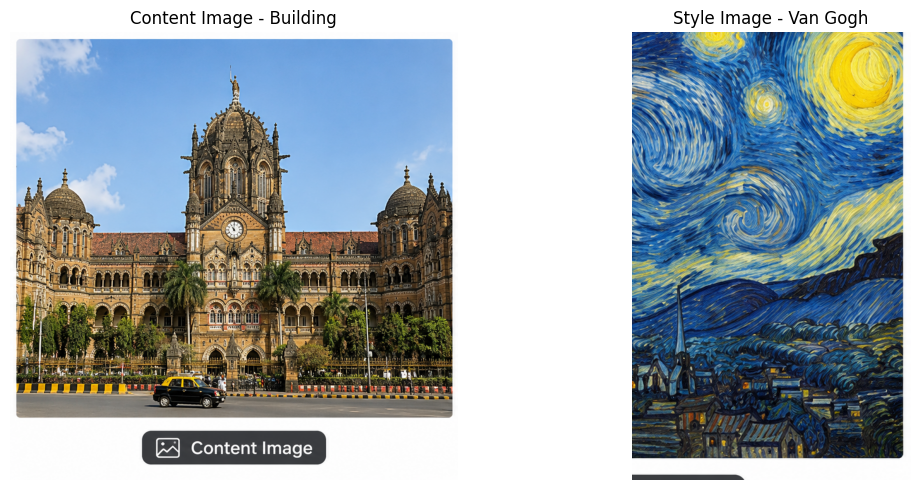

Content image: (887, 887)
Style image: (442, 710)


In [3]:

# Extract the right-hand painting from the comparison image
width, height = style_image.size

style_image = style_image.crop((
    width // 2,
    int(height * 0.10),
    width,
    int(height * 0.90)
))

# Display the corrected images
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(content_image)
axes[0].set_title("Content Image - Building")
axes[0].axis("off")

axes[1].imshow(style_image)
axes[1].set_title("Style Image - Van Gogh")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Content image:", content_image.size)
print("Style image:", style_image.size)


In [4]:

import torch
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Select GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGE_SIZE = 512

# VGG19 ImageNet normalization
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

preprocess = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Prepare tensors
content_tensor = preprocess(content_image).unsqueeze(0).to(device)
style_tensor = preprocess(style_image).unsqueeze(0).to(device)

print("Image preprocessing completed!")
print("Device:", device)
print("Content tensor:", content_tensor.shape)
print("Style tensor:", style_tensor.shape)

# Verify tensors
print("Content tensor range:",
      content_tensor.min().item(),
      content_tensor.max().item())


Image preprocessing completed!
Device: cuda
Content tensor: torch.Size([1, 3, 512, 512])
Style tensor: torch.Size([1, 3, 512, 512])
Content tensor range: -2.1179039478302 2.640000104904175


In [5]:

import torch
import torch.nn as nn
from torchvision import models

# Load pretrained VGG19
vgg = models.vgg19(
    weights=models.VGG19_Weights.DEFAULT
).features.to(device)

# Evaluation mode
vgg.eval()

# Freeze all VGG19 parameters
for parameter in vgg.parameters():
    parameter.requires_grad = False

# Selected feature layers
style_layers = {
    "0": "conv1_1",
    "5": "conv2_1",
    "10": "conv3_1",
    "19": "conv4_1",
    "28": "conv5_1"
}

content_layer = "21"  # conv4_2

# Feature extraction function
def get_features(image, model):
    features = {}

    x = image

    for name, layer in model._modules.items():
        x = layer(x)

        if name in style_layers:
            features[style_layers[name]] = x

        if name == content_layer:
            features["conv4_2"] = x

        if name == "28":
            break

    return features


# Extract features from both images
with torch.no_grad():
    content_features = get_features(content_tensor, vgg)
    style_features = get_features(style_tensor, vgg)

print("VGG19 loaded successfully!")
print("Device:", device)
print("\nExtracted Content Feature:")
print("conv4_2:", content_features["conv4_2"].shape)

print("\nExtracted Style Features:")
for name, feature in style_features.items():
    print(name, ":", feature.shape)

print("\nVGG19 feature extraction completed!")


Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:03<00:00, 163MB/s]


VGG19 loaded successfully!
Device: cuda

Extracted Content Feature:
conv4_2: torch.Size([1, 512, 64, 64])

Extracted Style Features:
conv1_1 : torch.Size([1, 64, 512, 512])
conv2_1 : torch.Size([1, 128, 256, 256])
conv3_1 : torch.Size([1, 256, 128, 128])
conv4_1 : torch.Size([1, 512, 64, 64])
conv4_2 : torch.Size([1, 512, 64, 64])
conv5_1 : torch.Size([1, 512, 32, 32])

VGG19 feature extraction completed!


In [6]:

def gram_matrix(tensor):

    batch_size, channels, height, width = tensor.size()

    # Reshape feature map
    features = tensor.view(
        batch_size,
        channels,
        height * width
    )

    # Calculate Gram Matrix
    gram = torch.bmm(
        features,
        features.transpose(1, 2)
    )

    # Normalize
    gram = gram / (channels * height * width)

    return gram


# Calculate Gram matrices for style features
style_grams = {}

for layer, feature in style_features.items():

    if layer != "conv4_2":
        style_grams[layer] = gram_matrix(feature).detach()


# Verify Gram matrices
print("Gram Matrix calculation completed!")

for layer, gram in style_grams.items():
    print(layer, ":", gram.shape)

print("\nTotal Gram matrices:", len(style_grams))


Gram Matrix calculation completed!
conv1_1 : torch.Size([1, 64, 64])
conv2_1 : torch.Size([1, 128, 128])
conv3_1 : torch.Size([1, 256, 256])
conv4_1 : torch.Size([1, 512, 512])
conv5_1 : torch.Size([1, 512, 512])

Total Gram matrices: 5


In [7]:

import torch
import torch.nn as nn

# Loss function
criterion = nn.MSELoss()

# Content loss
def calculate_content_loss(generated_features, content_features):
    return criterion(
        generated_features["conv4_2"],
        content_features["conv4_2"]
    )


# Style loss
def calculate_style_loss(generated_features, style_grams):

    style_loss = 0

    style_weights = {
        "conv1_1": 1.0,
        "conv2_1": 0.75,
        "conv3_1": 0.5,
        "conv4_1": 0.25,
        "conv5_1": 0.1
    }

    for layer, weight in style_weights.items():

        generated_gram = gram_matrix(
            generated_features[layer]
        )

        target_gram = style_grams[layer]

        layer_loss = criterion(
            generated_gram,
            target_gram
        )

        style_loss += weight * layer_loss

    return style_loss


# Loss weights
CONTENT_WEIGHT = 1
STYLE_WEIGHT = 1_000_000

print("Loss functions initialized!")
print("Content weight:", CONTENT_WEIGHT)
print("Style weight:", STYLE_WEIGHT)
print("Loss function: Mean Squared Error")


Loss functions initialized!
Content weight: 1
Style weight: 1000000
Loss function: Mean Squared Error


In [8]:

with torch.no_grad():

    test_features = get_features(content_tensor, vgg)

    test_content_loss = calculate_content_loss(
        test_features,
        content_features
    )

    test_style_loss = calculate_style_loss(
        test_features,
        style_grams
    )

    test_total_loss = (
        CONTENT_WEIGHT * test_content_loss +
        STYLE_WEIGHT * test_style_loss
    )

print("Loss calculation test completed!")
print("Content Loss:", test_content_loss.item())
print("Style Loss:", test_style_loss.item())
print("Total Loss:", test_total_loss.item())


Loss calculation test completed!
Content Loss: 0.0
Style Loss: 0.0009570655529387295
Total Loss: 957.0655517578125


Generated image initialized successfully!
Image shape: torch.Size([1, 3, 512, 512])
Learning rate: 0.003
Optimization epochs: 500
Device: cuda


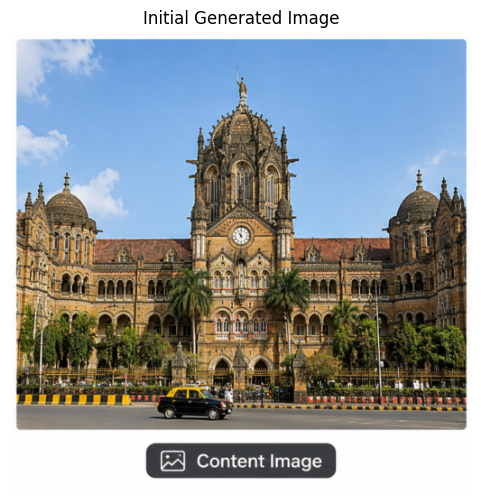

In [9]:

import torch
import torch.optim as optim
import matplotlib.pyplot as plt

# Initialize generated image from content image
generated_image = content_tensor.clone().detach()
generated_image.requires_grad_(True)

# Adam optimizer
optimizer = optim.Adam(
    [generated_image],
    lr=0.003
)

# Training configuration
EPOCHS = 500

print("Generated image initialized successfully!")
print("Image shape:", generated_image.shape)
print("Learning rate:", 0.003)
print("Optimization epochs:", EPOCHS)
print("Device:", device)

# Display initial generated image
def denormalize(tensor):
    mean_tensor = torch.tensor(
        mean, device=tensor.device
    ).view(1, 3, 1, 1)

    std_tensor = torch.tensor(
        std, device=tensor.device
    ).view(1, 3, 1, 1)

    return tensor * std_tensor + mean_tensor


initial_image = denormalize(
    generated_image.detach()
).clamp(0, 1)

plt.figure(figsize=(6, 6))
plt.imshow(
    initial_image.squeeze(0).permute(1, 2, 0).cpu()
)
plt.title("Initial Generated Image")
plt.axis("off")
plt.show()


In [10]:

import time

# Optimization settings
EPOCHS = 500
PRINT_EVERY = 50

# Track losses
loss_history = []

print("Starting Neural Style Transfer...")
start_time = time.time()

for epoch in range(1, EPOCHS + 1):

    optimizer.zero_grad()

    # Extract generated image features
    generated_features = get_features(
        generated_image,
        vgg
    )

    # Calculate content and style losses
    content_loss = calculate_content_loss(
        generated_features,
        content_features
    )

    style_loss = calculate_style_loss(
        generated_features,
        style_grams
    )

    total_loss = (
        CONTENT_WEIGHT * content_loss +
        STYLE_WEIGHT * style_loss
    )

    # Backpropagation
    total_loss.backward()
    optimizer.step()

    # Keep normalized image values within valid bounds
    with torch.no_grad():
        generated_image.copy_(
            torch.maximum(
                torch.minimum(
                    generated_image,
                    torch.tensor(
                        (1 - torch.tensor(mean, device=device).view(1, 3, 1, 1))
                        / torch.tensor(std, device=device).view(1, 3, 1, 1),
                        device=device
                    )
                ),
                torch.tensor(
                    (0 - torch.tensor(mean, device=device).view(1, 3, 1, 1))
                    / torch.tensor(std, device=device).view(1, 3, 1, 1),
                    device=device
                )
            )
        )

    loss_history.append(total_loss.item())

    if epoch % PRINT_EVERY == 0:
        print(
            f"Epoch [{epoch}/{EPOCHS}] | "
            f"Content Loss: {content_loss.item():.4f} | "
            f"Style Loss: {style_loss.item():.6f} | "
            f"Total Loss: {total_loss.item():.4f}"
        )

print("\nOptimization completed!")
print("Time taken:", round(time.time() - start_time, 2), "seconds")


Starting Neural Style Transfer...


/tmp/ipykernel_304/3533884922.py:49: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(
/tmp/ipykernel_304/3533884922.py:55: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(


Epoch [50/500] | Content Loss: 6.2629 | Style Loss: 0.000121 | Total Loss: 126.7872
Epoch [100/500] | Content Loss: 7.1902 | Style Loss: 0.000074 | Total Loss: 81.3091
Epoch [150/500] | Content Loss: 7.6139 | Style Loss: 0.000054 | Total Loss: 61.4577
Epoch [200/500] | Content Loss: 7.8574 | Style Loss: 0.000042 | Total Loss: 50.1399
Epoch [250/500] | Content Loss: 7.9771 | Style Loss: 0.000035 | Total Loss: 42.9771
Epoch [300/500] | Content Loss: 8.0066 | Style Loss: 0.000030 | Total Loss: 38.0787
Epoch [350/500] | Content Loss: 7.9877 | Style Loss: 0.000026 | Total Loss: 34.4828
Epoch [400/500] | Content Loss: 7.9428 | Style Loss: 0.000024 | Total Loss: 31.7130
Epoch [450/500] | Content Loss: 7.8876 | Style Loss: 0.000022 | Total Loss: 29.4912
Epoch [500/500] | Content Loss: 7.8226 | Style Loss: 0.000020 | Total Loss: 27.6558

Optimization completed!
Time taken: 51.13 seconds


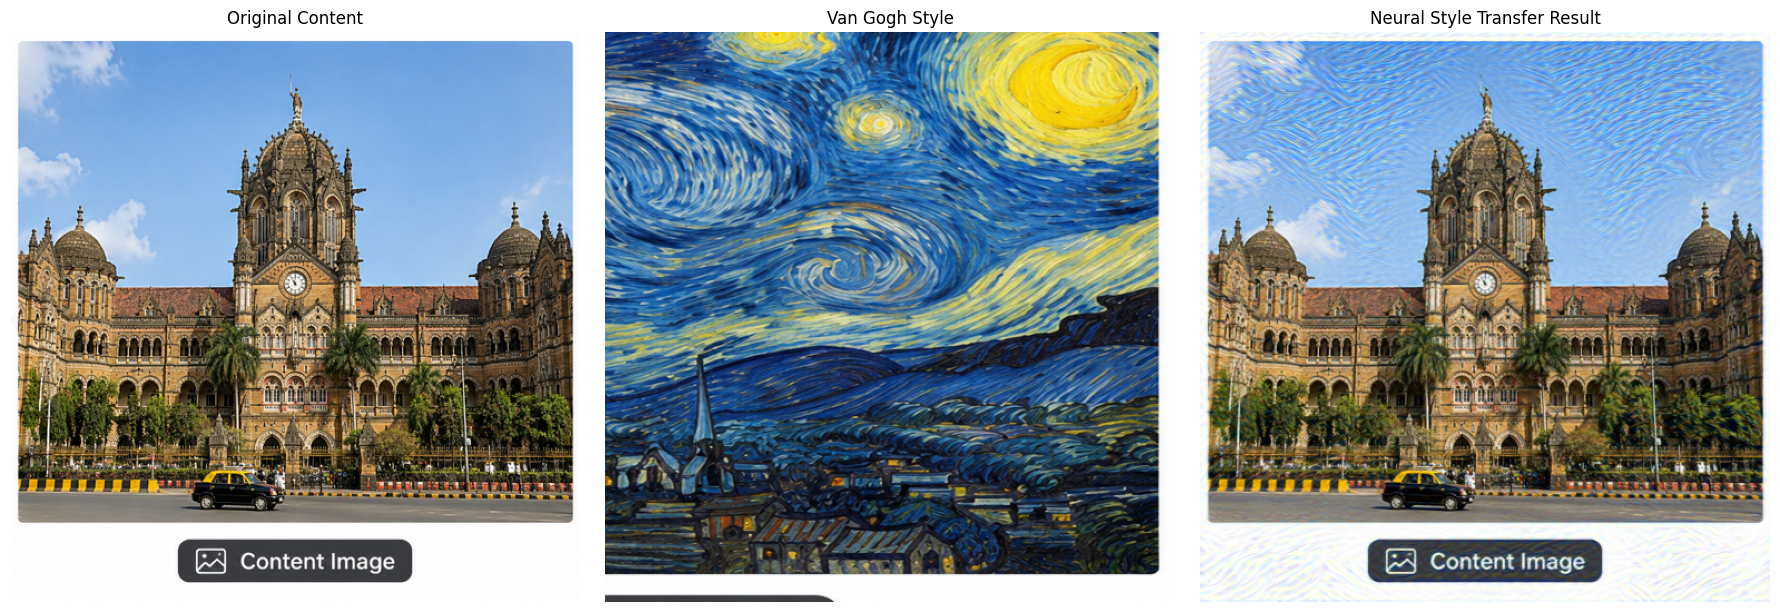

In [11]:

# Convert optimized tensor to displayable image
final_image = denormalize(
    generated_image.detach()
).clamp(0, 1)

# Display original, style and generated images
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(content_image.resize((512, 512)))
axes[0].set_title("Original Content")
axes[0].axis("off")

axes[1].imshow(style_image.resize((512, 512)))
axes[1].set_title("Van Gogh Style")
axes[1].axis("off")

axes[2].imshow(
    final_image.squeeze(0).permute(1, 2, 0).cpu()
)
axes[2].set_title("Neural Style Transfer Result")
axes[2].axis("off")

plt.tight_layout()
plt.show()


In [12]:

# Save the first experiment
first_result = generated_image.detach().clone()

# Start second experiment from original content
generated_image = content_tensor.clone().detach()
generated_image.requires_grad_(True)

# Stronger style influence
CONTENT_WEIGHT = 1
STYLE_WEIGHT = 5_000_000

optimizer = torch.optim.Adam(
    [generated_image],
    lr=0.003
)

EPOCHS = 500
loss_history_strong = []

print("Starting stronger style transfer...")

for epoch in range(1, EPOCHS + 1):

    optimizer.zero_grad()

    generated_features = get_features(
        generated_image, vgg
    )

    content_loss = calculate_content_loss(
        generated_features, content_features
    )

    style_loss = calculate_style_loss(
        generated_features, style_grams
    )

    total_loss = (
        CONTENT_WEIGHT * content_loss +
        STYLE_WEIGHT * style_loss
    )

    total_loss.backward()
    optimizer.step()

    with torch.no_grad():
        generated_image.copy_(
            torch.maximum(
                torch.minimum(
                    generated_image,
                    (1 - torch.tensor(mean, device=device).view(1,3,1,1))
                    / torch.tensor(std, device=device).view(1,3,1,1)
                ),
                (0 - torch.tensor(mean, device=device).view(1,3,1,1))
                / torch.tensor(std, device=device).view(1,3,1,1)
            )
        )

    loss_history_strong.append(total_loss.item())

    if epoch % 100 == 0:
        print(
            f"Epoch {epoch}/{EPOCHS} | "
            f"Content: {content_loss.item():.4f} | "
            f"Style: {style_loss.item():.6f} | "
            f"Total: {total_loss.item():.4f}"
        )

print("Stronger style transfer completed!")


Starting stronger style transfer...
Epoch 100/500 | Content: 8.0672 | Style: 0.000073 | Total: 375.2328
Epoch 200/500 | Content: 9.5511 | Style: 0.000041 | Total: 215.3609
Epoch 300/500 | Content: 10.3412 | Style: 0.000029 | Total: 154.4553
Epoch 400/500 | Content: 10.7858 | Style: 0.000022 | Total: 122.7982
Epoch 500/500 | Content: 11.0645 | Style: 0.000018 | Total: 102.8649
Stronger style transfer completed!


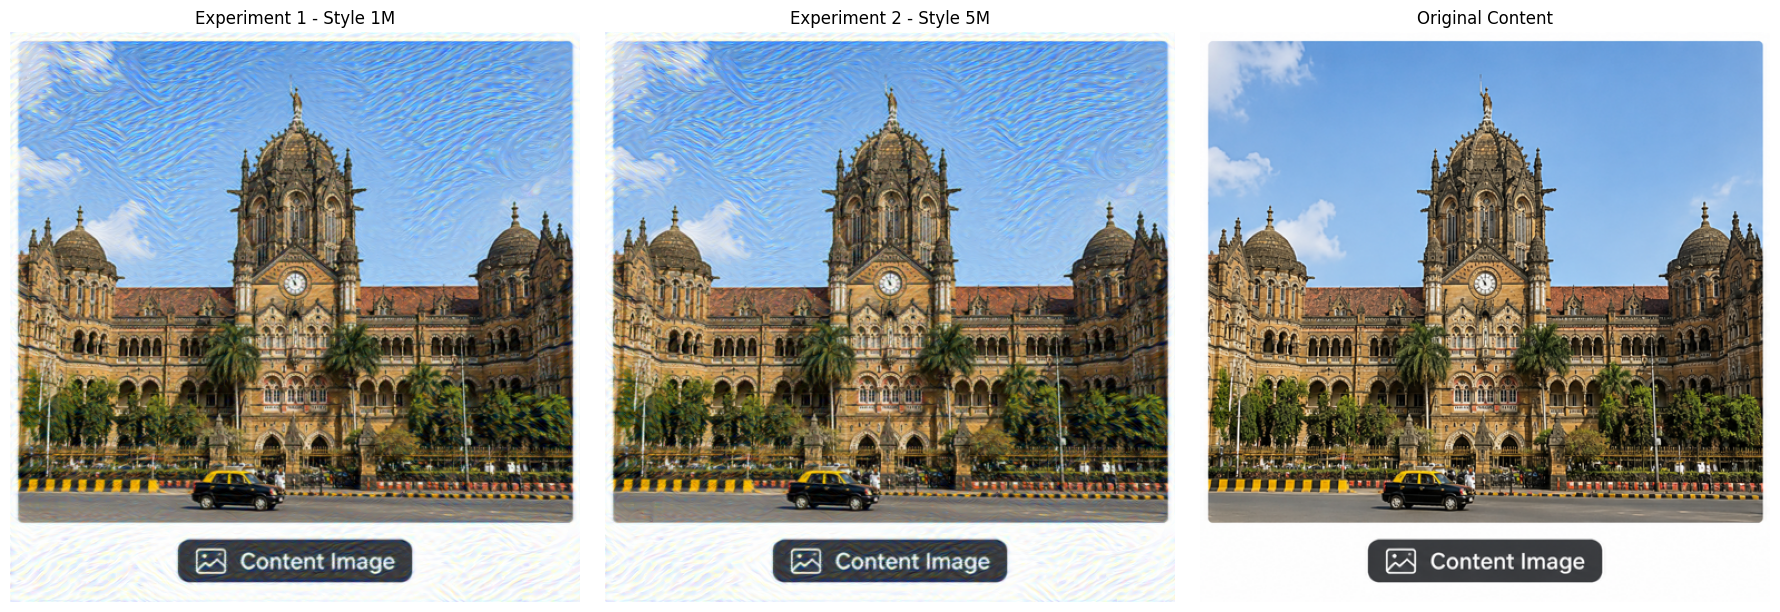

In [13]:

# Convert both experiments to displayable images
result_1 = denormalize(first_result).clamp(0, 1)
result_2 = denormalize(generated_image.detach()).clamp(0, 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(
    result_1.squeeze(0).permute(1, 2, 0).cpu()
)
axes[0].set_title("Experiment 1 - Style 1M")
axes[0].axis("off")

axes[1].imshow(
    result_2.squeeze(0).permute(1, 2, 0).cpu()
)
axes[1].set_title("Experiment 2 - Style 5M")
axes[1].axis("off")

axes[2].imshow(content_image.resize((512, 512)))
axes[2].set_title("Original Content")
axes[2].axis("off")

plt.tight_layout()
plt.show()


In [14]:

import os
import json
import torch
from torchvision.utils import save_image

os.makedirs("Neural_Style_Transfer/results", exist_ok=True)
os.makedirs("Neural_Style_Transfer/images", exist_ok=True)

# Save original inputs
content_display = transforms.Resize((512, 512))(content_image)
style_display = transforms.Resize((512, 512))(style_image)

content_display.save(
    "Neural_Style_Transfer/images/content_image.png"
)

style_display.save(
    "Neural_Style_Transfer/images/style_image.png"
)

# Save Experiment 1
save_image(
    denormalize(first_result).clamp(0, 1),
    "Neural_Style_Transfer/results/style_weight_1M.png"
)

# Save Experiment 2
save_image(
    denormalize(generated_image.detach()).clamp(0, 1),
    "Neural_Style_Transfer/results/style_weight_5M.png"
)

# Save evaluation data
results = {
    "project": "Neural Style Transfer",
    "model": "Pretrained VGG19",
    "device": str(device),
    "image_size": "512x512",
    "optimization_epochs": 500,
    "optimizer": "Adam",
    "learning_rate": 0.003,
    "content_weight": 1,
    "experiments": {
        "style_weight_1M": {
            "style_weight": 1000000,
            "content_loss": 7.8226,
            "style_loss": 0.000020,
            "total_loss": 27.6558
        },
        "style_weight_5M": {
            "style_weight": 5000000,
            "content_loss": 11.0645,
            "style_loss": 0.000018,
            "total_loss": 102.8649
        }
    }
}

with open(
    "Neural_Style_Transfer/results/evaluation_results.json",
    "w"
) as file:
    json.dump(results, file, indent=4)

# Save loss history
with open(
    "Neural_Style_Transfer/results/loss_history.json",
    "w"
) as file:
    json.dump({
        "experiment_1": loss_history,
        "experiment_2": loss_history_strong
    }, file, indent=4)

print("Final results saved successfully!")
print("Experiment 1 saved.")
print("Experiment 2 saved.")
print("Evaluation report saved.")
print("Loss history saved.")


Final results saved successfully!
Experiment 1 saved.
Experiment 2 saved.
Evaluation report saved.
Loss history saved.


In [15]:

import os
import zipfile

project_folder = "Neural_Style_Transfer"
zip_filename = "Neural_Style_Transfer.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files_list in os.walk(project_folder):
        for filename in files_list:
            file_path = os.path.join(root, filename)
            zipf.write(file_path, file_path)

print("Project ZIP created successfully!")
print("File:", zip_filename)
print("Project contents:")

for root, dirs, files_list in os.walk(project_folder):
    for filename in files_list:
        print(os.path.join(root, filename))


Project ZIP created successfully!
File: Neural_Style_Transfer.zip
Project contents:
Neural_Style_Transfer/results/style_weight_1M.png
Neural_Style_Transfer/results/loss_history.json
Neural_Style_Transfer/results/evaluation_results.json
Neural_Style_Transfer/results/style_weight_5M.png
Neural_Style_Transfer/images/content_image.png
Neural_Style_Transfer/images/style_image.png


In [16]:
from google.colab import files
files.download("Neural_Style_Transfer.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>